# 04 Video SOTA - arquitecturas actuales + demo T4 (punto 4)


Fuentes: papers 07 DiT, 15 CogVideoX, 16 Hunyuan, 17 Wan, 18 LTX, 19 MovieGen, 20 Sora, 22 FM + repos diffusers/CogVideo/Open-Sora. Ver NOTAS 3 y REPOS 2.


### Tipos de arquitectura video (detalle para informe punto 4)
**1. U-Net espacio-temporal (VDM):** extiende la U-Net de imagen con convoluciones espaciales y bloques de atención temporal, a menudo factorizados para limitar memoria. Modela clips cortos; extender duración o resolución requiere estrategias adicionales. Ver papers 10/11.
**2. Imagen a video en espacio latente (SVD):** parte de una imagen y añade capacidad temporal a una representación latente de imagen. El preentrenamiento de imagen seguido de entrenamiento de video facilita reutilizar conocimiento visual; no debe confundirse con un modelo general de texto a video. Ver paper 13.
**3. DiT para video:** convierte latentes en tokens o parches espacio-temporales y aplica bloques Transformer. La atención conjunta puede ser costosa; existen diseños factorados e híbridos. Sora, HunyuanVideo y CogVideoX no deben presentarse como una implementación idéntica. Ver papers 07, 15, 16 y 20.
**4. Diseños multimodales distintos:** SD3 introduce MM-DiT para generación de imágenes y sirve como antecedente, no como modelo de video. HunyuanVideo usa un diseño de doble flujo que converge a flujo único; CogVideoX usa un Expert Transformer con tratamiento por modalidad; Wan tiene su propio diseño DiT. No son sinónimos. Ver papers 15, 16, 17 y 23.
**5. Eficiencia:** LTX-Video prioriza una representación latente muy comprimida; SANA-Video explora atención lineal y caché temporal. Son estrategias distintas para reducir costo, no una arquitectura compartida. Ver papers 18 y 21.
**6. Audio y video:** algunos sistemas ofrecen generación de ambas modalidades, pero no se debe asumir que usan un único denoiser conjunto. MovieGen describe modelos de video y audio relacionados. Ver paper 19.
Elegimos **CogVideoX-2B** para la demo por disponibilidad en Diffusers; la demo no demuestra que sea el mejor modelo ni que quepa en cualquier T4.

## 1. Flujo completo de generación

Un video se representa como una secuencia ordenada de fotogramas. El modelo aprende tanto apariencia espacial como cambios entre fotogramas; por eso la tarea no equivale a generar imágenes independientes y unirlas. El flujo típico tiene estas etapas:

1. **Datos y captions.** Se filtran clips por calidad, duración, movimiento, duplicados y seguridad. Un caption denso describe sujetos, acciones, escena y cámara. Descripciones poco alineadas o datos repetidos degradan el seguimiento de instrucciones y la diversidad.
2. **Compresión espacio-temporal.** Un VAE codifica los fotogramas a latentes de menor resolución y, a veces, reduce también la cantidad de pasos temporales. El latente puede representarse como tiempo × alto × ancho × canales. Un VAE causal produce cada grupo temporal usando el pasado y facilita decodificación por bloques; no todos los modelos usan el mismo factor de compresión.
3. **Tokens del backbone.** La secuencia latente se divide en parches o tokens espacio-temporales. Se incorpora información de posición y de paso de ruido. Reducir tokens ahorra cómputo, pero demasiada compresión puede borrar detalles finos o movimientos pequeños.
4. **Condicionamiento.** El caption pasa por un encoder de texto, por ejemplo T5 o CLIP. Sus embeddings llegan al backbone mediante cross-attention, atención multimodal o bloques especializados. En image-to-video también se puede condicionar con una imagen inicial, embeddings de imagen, máscara o controles de movimiento. El texto no pasa por el encoder VAE de video.
5. **Objetivo de aprendizaje.** Se perturba el latente real con ruido en difusión, o se define una trayectoria entre ruido y dato en Flow Matching. El backbone recibe el latente perturbado, el tiempo y el condicionamiento; aprende a predecir una cantidad que permita revertir o seguir esa trayectoria.
6. **Muestreo y decodificación.** En inferencia se inicia desde ruido y se aplican pasos de sampler guiados por el texto. El latente final se decodifica con el VAE a fotogramas; luego puede haber super-resolución espacial o temporal. FPS, duración y resolución dependen del modelo y del presupuesto de cómputo.

## 2. Evolución de las arquitecturas

### U-Net 3D y atención factorizada

Video Diffusion Models (2022) adapta la U-Net de imagen a bloques de video. Las convoluciones espaciales pueden operar por fotograma y los bloques temporales relacionan posiciones entre fotogramas. Factorizar atención espacial y temporal evita construir una matriz de atención conjunta sobre todos los tokens. El trabajo también muestra entrenamiento conjunto con imágenes y video y extensión autoregresiva: generar un bloque y usarlo como condición del siguiente. Es un punto de partida, no la descripción de todos los modelos actuales.

### Cascadas y separación de tareas

Imagen Video usa un modelo base de texto a video y etapas de super-resolución espacial y temporal. La cascada permite que cada red resuelva una escala, a costa de varias inferencias y posibles errores acumulados entre etapas. Make-A-Video explora otra idea: combinar conocimiento de pares texto-imagen con patrones de movimiento aprendidos de videos sin caption alineado, reduciendo la dependencia de pares texto-video.

### Modelos latentes y transferencia desde imagen

Stable Video Diffusion toma una imagen como condición y genera movimiento en latente. Su receta por etapas reutiliza modelos de imagen y luego adapta a video con datos seleccionados y afinados. Esta ruta es adecuada para image-to-video, pero no equivale a un generador de texto a video sin imagen de referencia.

### DiT y tokens espacio-temporales

Un Diffusion Transformer reemplaza bloques convolucionales de U-Net por bloques Transformer sobre tokens. La atención conjunta permite interacción global entre posiciones, pero su costo crece aproximadamente con el cuadrado del número de tokens. La atención factorada separa ejes espaciales y temporales; ventanas, compresión temporal y cachés reducen costo con posibles límites en alcance global o detalle. DiT describe una familia de backbones, no un único método de entrenamiento ni una garantía automática de calidad.

### Diseños multimodales

MM-DiT de Stable Diffusion 3 mantiene representaciones de texto e imagen con proyecciones propias e interacción de atención; es un modelo de imagen. HunyuanVideo lleva ideas multimodales a video con etapas de doble flujo y flujo único. CogVideoX emplea un Expert Transformer con rutas o normalizaciones especializadas para modalidades. Wan2.1 es una arquitectura propia con VAE espacio-temporal y backbone Wan-DiT. La etiqueta MM-DiT no debe aplicarse indiscriminadamente a todos ellos.

## 3. Objetivos: difusión y Flow Matching

En **DDPM**, durante entrenamiento se agrega ruido al dato según un schedule. Una parametrización frecuente predice el ruido epsilon; otras predicen el dato limpio o la velocidad v, combinación de señal y ruido. Cambia el objetivo numérico y la parametrización, no el hecho de que la generación recorra pasos de eliminación de ruido. La predicción v aparece en algunos modelos de video y puede comportarse favorablemente en distintos niveles de ruido.

En **Flow Matching**, el modelo aprende un campo vectorial que transporta muestras desde una distribución inicial hacia datos. Rectified Flow usa una trayectoria simple entre ruido y dato como objetivo de velocidad. En inferencia se integra el campo con un solver numérico; el número de evaluaciones y la calidad dependen del modelo, la trayectoria y el solver. Flow Matching no significa que el modelo no use latentes ni que genere en un solo paso.

La **Classifier-Free Guidance (CFG)** combina una predicción condicionada con otra sin condición. Aumentar la escala suele reforzar la adherencia al prompt, pero puede reducir diversidad y producir artefactos; no existe una escala óptima universal.

## 4. Condicionamiento, duración y sistemas

Los encoders T5 y CLIP producen señales de texto con propiedades distintas; algunas tuberías combinan más de un encoder o reescriben captions. Cross-attention consulta los embeddings de texto desde los tokens de video. Los diseños multimodales pueden concatenar tokens o mantener rutas separadas. Para image-to-video, la imagen inicial aporta identidad y composición, mientras el modelo aprende el movimiento compatible. CFG requiere entrenamiento con condiciones descartadas o una estimación incondicional equivalente.

Para clips largos se usan bloques autoregresivos, ventanas, solapamiento o cachés de atención. Generar el bloque siguiente condicionado en el anterior ahorra memoria frente a modelar una secuencia completa, pero puede acumular deriva y perder identidad. La super-resolución espacial y la interpolación temporal pueden añadir detalle, aunque no recuperan información que el modelo base nunca generó.

## 5. Lectura correcta del estado del arte

La calidad depende conjuntamente de datos, resolución y duración de entrenamiento, codec, backbone, condicionamiento, objetivo, sampler y evaluación. Más parámetros no resuelven por sí solos consistencia temporal, física o seguimiento de instrucciones. Las cifras de modelos distintos no son comparables si cambian resolución, número de fotogramas, prompts, tamaño de muestra, decoder o protocolo de benchmark.

Este panorama se limita a las referencias locales de 2022–2025; no es un ranking en vivo ni un inventario exhaustivo de lanzamientos de 2026. La tabla separa modelos y objetivos para evitar una falsa arquitectura única. Se omiten cifras de VRAM: varían con resolución, cuantización, atención eficiente, offload y versión del código.


### Tabla SOTA (para informe punto 4)
| Modelo | VAE / latente | Backbone y atención | Objetivo / condición | Enfoque y cautela |
|---|---|---|---|---|
| CogVideoX-2B | VAE causal 3D | Expert Transformer; tokens de video y texto | difusión con v-pred; texto T5 | demo del notebook; memoria depende de configuración |
| CogVideoX-5B | VAE causal 3D | Expert Transformer; tokens de video y texto | difusión condicionada por texto | variante mayor; no comparar memoria sin fijar resolución y precisión |
| HunyuanVideo | VAE causal 3D | MM-DiT de doble flujo a flujo único | Flow Matching; texto multimodal | su diseño no es el Expert Transformer de CogVideoX |
| Wan2.1 | VAE espacio-temporal Wan | Wan-DiT y condicionamiento de texto | Flow Matching | arquitectura propia; no llamarla MM-DiT dual-to-single sin sustento |
| LTX-Video | Video-VAE espacio-temporal, compresión 1:192 | DiT con atención espacio-temporal completa | difusión latente; texto e imagen | el decoder participa en el último denoising; compresión extrema limita detalle fino |

### Modelos de gran escala y sistemas cerrados

| Modelo | VAE / latente | Backbone y atención | Objetivo / condición | Enfoque y cautela |
|---|---|---|---|---|
| MovieGen | codec/tokenizador de video | Transformer de video; modelo de audio descrito aparte | Flow Matching; texto y edición | no asumir un único denoiser conjunto de audio-video |
| Sora | compresión y parches espacio-temporales según fuentes públicas | Transformer descrito en reportes, detalles internos no confirmados | objetivo y entrenamiento no publicados en detalle | sistema cerrado; distinguir hechos publicados de inferencia |
Demo selecciona CogVideoX-2B; no implica que otros modelos usen la misma arquitectura ni que la comparación sea un benchmark controlado.

### Referentes históricos y relacionados

| Modelo | VAE / latente | Backbone y atención | Objetivo / condición | Enfoque y cautela |
|---|---|---|---|---|
| Video Diffusion Models | latente de video | U-Net 3D con atención espacial/temporal | DDPM; texto opcional | referencia inicial; clips cortos y extensión por bloques |
| Imagen Video | latente y etapas de super-resolución | cascada de modelo base, SR espacial y SR temporal | difusión condicionada por texto | costo de inferencia acumulado |
| Make-A-Video | representaciones de imagen/video | modelo de imagen con componentes temporales | conocimiento texto-imagen + movimiento de videos | reduce dependencia de pares texto-video |
| Stable Video Diffusion | latente de imagen/video | backbone de imagen adaptado con módulos temporales | difusión condicionada por imagen | principalmente image-to-video |
| SD3, relacionado | latente de imagen, no de video | MM-DiT con flujos de texto e imagen | Rectified Flow | antecedente arquitectónico; no es generador de video |
| SANA-Video | latente de video | Block Linear DiT y caché autoregresiva de estado constante | difusión condicionada por texto | diseñada para eficiencia y clips largos; distinta de la compresión de LTX |


### Diagrama ejemplo (CogVideoX-2B)
Rama de texto: prompt -> encoder T5 -> condición del Transformer. Rama de video: fotogramas -> encoder VAE causal 3D -> latentes perturbados -> parches espacio-temporales -> Expert Transformer -> pasos de denoising -> decoder VAE 3D -> fotogramas. El texto no atraviesa el VAE.


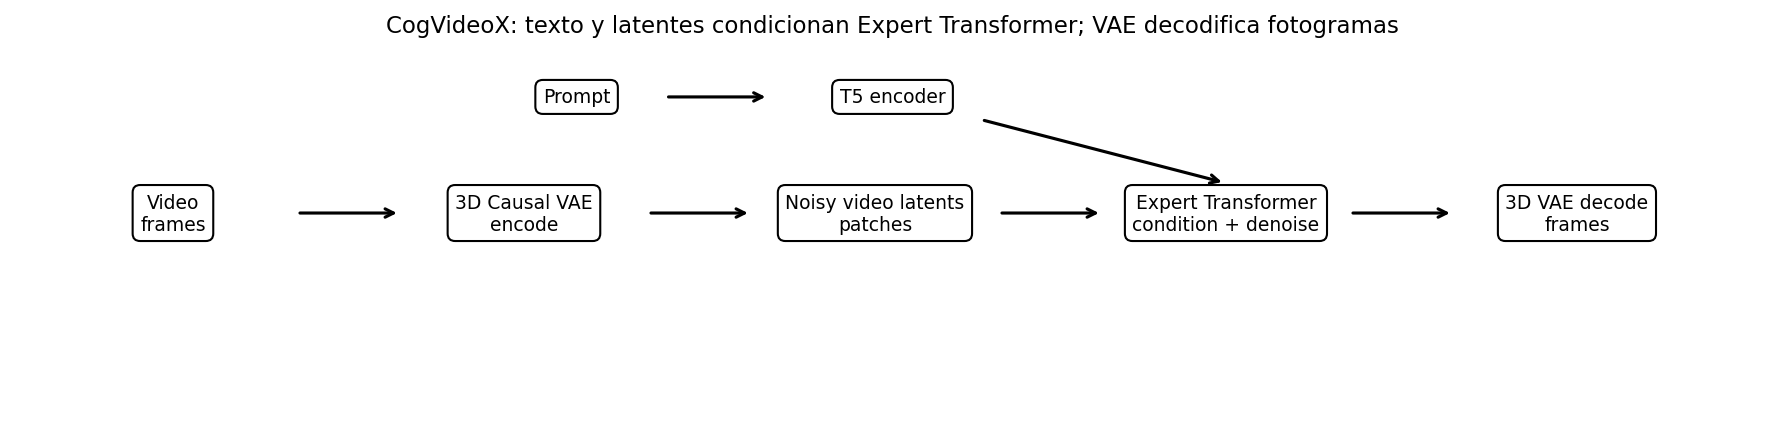

In [1]:
# Diagrama CogVideoX-2B ejemplo
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12,3), dpi=150)
ax.axis("off")
boxes=[("Video\nframes",0.02),("3D Causal VAE\nencode",0.22),("Noisy video latents\npatches",0.42),("Expert Transformer\ncondition + denoise",0.62),("3D VAE decode\nframes",0.82)]
for label,x in boxes:
    ax.text(x+0.07,0.55,label,ha="center",va="center",fontsize=9,bbox=dict(boxstyle="round,pad=0.4",fc="white",ec="black"))
    if x<0.8: ax.annotate("",xy=(x+0.20,0.55),xytext=(x+0.14,0.55),arrowprops=dict(arrowstyle="->",lw=1.5))
ax.text(0.32,0.86,"Prompt",ha="center",va="center",fontsize=9,bbox=dict(boxstyle="round,pad=0.4",fc="white",ec="black"))
ax.text(0.50,0.86,"T5 encoder",ha="center",va="center",fontsize=9,bbox=dict(boxstyle="round,pad=0.4",fc="white",ec="black"))
ax.annotate("",xy=(0.43,0.86),xytext=(0.37,0.86),arrowprops=dict(arrowstyle="->",lw=1.5))
ax.annotate("",xy=(0.69,0.63),xytext=(0.55,0.80),arrowprops=dict(arrowstyle="->",lw=1.5))
ax.set_title("CogVideoX: texto y latentes condicionan Expert Transformer; VAE decodifica fotogramas",fontsize=11)
plt.tight_layout(); plt.show()


In [2]:
%pip install -q diffusers transformers accelerate
import torch
print(torch.cuda.is_available())


True


### Demo T4: CogVideoX-2B t2v 33 frames (chiquito para que quepa)
Usa offload + slicing + tiling (apuntes REPOS 3.3). Si OOM baja a 17 frames.


In [3]:
import torch
from diffusers import CogVideoXPipeline
from diffusers.utils import export_to_video
pipe=CogVideoXPipeline.from_pretrained("THUDM/CogVideoX-2b", torch_dtype=torch.float16)
pipe.enable_sequential_cpu_offload()
pipe.vae.enable_slicing()
pipe.vae.enable_tiling()
print("pipe OK CogVideoX-2B")


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


model_index.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

pipe OK CogVideoX-2B


  0%|          | 0/20 [00:00<?, ?it/s]

frames: 33 (720, 480)


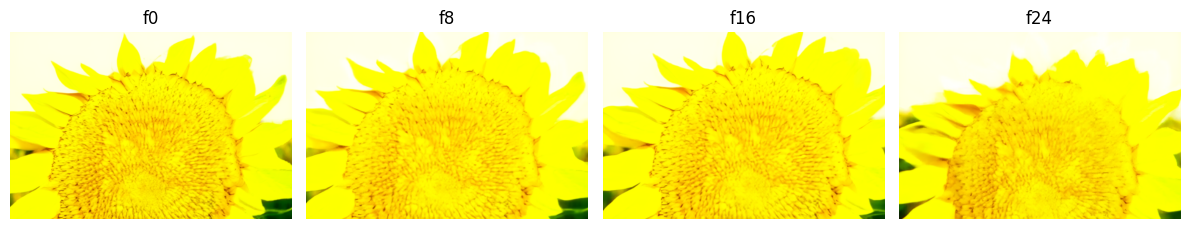

In [4]:
prompt="a sunflower field swaying in the wind, close-up, daylight"
video=pipe(prompt, num_frames=33, num_inference_steps=20, guidance_scale=6.0).frames[0]
export_to_video(video, "demo_video.mp4", fps=8)
print("frames:", len(video), video[0].size)
import matplotlib.pyplot as plt
plt.figure(figsize=(12,3))
k=0
for i in [0,8,16,24]:
    plt.subplot(1,4,k+1); plt.imshow(video[i]); plt.axis("off"); plt.title(f"f{i}"); k+=1
plt.tight_layout(); plt.show()
from IPython.display import Video
Video("demo_video.mp4", embed=True, width=480)


## Evaluación, límites y referencias
**FVD (Fréchet Video Distance)** compara distribuciones de características de clips reales y generados, normalmente extraídas por una red de video preentrenada. Menor suele indicar mayor similitud bajo ese extractor; no prueba que la física sea correcta ni que cada prompt se haya seguido. Depende de cantidad y selección de clips, resolución, FPS, recorte y extractor. Comparar FVD publicados solo es razonable si el protocolo coincide. Video Diffusion Models (paper 10) reporta FVD y cita el trabajo original de Unterthiner et al.

**VBench** es una suite de evaluación por dimensiones, por ejemplo consistencia del sujeto, suavidad del movimiento, calidad visual y alineación con el prompt. Un promedio puede ocultar una dimensión débil; los evaluadores automáticos también heredan sesgos y límites de sus modelos. Conviene acompañar los puntajes con clips representativos y revisión humana.

### Retos abiertos

- **Consistencia temporal e identidad:** mantener sujetos, vestuario, objetos y geometría entre planos y cambios de cámara.
- **Movimiento y causalidad:** representar contacto, gravedad, oclusión y continuidad sin deformaciones.
- **Duración:** la generación por bloques puede acumular deriva; aumentar contexto exige memoria y cómputo.
- **Control:** prompts largos, composición exacta, edición localizada, cámara y sincronía audio-video siguen siendo difíciles.
- **Datos e infraestructura:** curación, captions densos, derechos, costo energético y acceso a aceleradores condicionan los resultados.
- **Evaluación y seguridad:** métricas no sustituyen revisión humana; siguen riesgos de sesgo, privacidad, deepfakes y procedencia.

### Referencias usadas

- Ho et al., **Video Diffusion Models**, `papers_md/10-VideoDiffusion-2204.03458.md`.
- Ho et al., **Imagen Video**, `papers_md/11-ImagenVideo-2210.02303.md`.
- Singer et al., **Make-A-Video**, `papers_md/12-MakeAVideo-2209.14792.md`.
- Blattmann et al., **Stable Video Diffusion**, `papers_md/13-StableVideoDiffusion-2311.15127.md`.
- **CogVideoX**, `papers_md/15-CogVideoX-2408.06072.md`; **HunyuanVideo**, `papers_md/16-HunyuanVideo-2412.03603.md`; **Wan**, `papers_md/17-Wan21-2503.20314.md`.
- **LTX-Video**, `papers_md/18-LTXVideo-2501.00103.md`; **MovieGen**, `papers_md/19-MovieGen-2410.13720.md`; **Sora review**, `papers_md/20-SoraReview-2402.17177.md`.
- **SANA-Video**, `papers_md/21-SANA-Video-2509.24695.md`; **Flow Matching**, `papers_md/22-FlowMatching-2210.02747.md`; **Stable Diffusion 3 / MM-DiT**, `papers_md/23-SD3-MM-DiT-2403.03206.md`.
- Peebles y Xie, **DiT**, `papers_md/07-DiT-2212.09748.md`.
- **VBench**, benchmark de Vchitect, referencia local: `REPOS_ESTADO_DEL_ARTE_Y_CODIGO.md`; Unterthiner et al., **Towards Accurate Generative Models of Video: A New Metric & Challenges** (2018, arXiv:1812.01717), citado en paper 10.

### Síntesis

No hay un ganador universal. La elección depende de si se prioriza texto-a-video o imagen-a-video, duración, control, consistencia, resolución, apertura de pesos y presupuesto de inferencia. La demo CogVideoX ilustra una tubería ejecutable; no reemplaza la comparación experimental con prompts, resolución, FPS, número de muestras y hardware controlados.
